# 06 — Fiches d'alerte rédigées par un LLM

**Projet Horizon : décrochage et tutorat** — tâches LL-01 (fiches) et LL-02 (évaluation et version 2 du prompt).

Ce notebook lit les fichiers produits par `python run_all.py` (`data/processed/`) et les fiches générées par `python -m src.llm --generer`, enregistrées dans le dépôt : il ne relance pas le pipeline et **n'appelle jamais l'API** ; il tourne de haut en bas sans clé. Le code est dans `src/llm.py`, les gabarits du prompt dans `src/prompts/fiche_v1.md` et `src/prompts/fiche_v2.md`. Décisions appliquées : D-63 à D-69.

In [1]:
import collections
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

# Le notebook est dans notebooks/ : on remonte jusqu'à la racine du dépôt (dossier qui
# contient src/config.py) pour pouvoir importer src/, quel que soit le dossier de lancement.
racine = Path.cwd()
while not (racine / "src" / "config.py").exists():
    racine = racine.parent
sys.path.insert(0, str(racine))

from src import config, eda, llm

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
config.DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)
SEMAINE = config.SEMAINE_FICHES


def enregistrer(figure, nom):
    """Enregistre une figure en PNG dans docs/figures/ et l'affiche."""
    figure.tight_layout()
    figure.savefig(config.DOSSIER_FIGURES / nom, dpi=120)
    plt.show()


def nombre(x, decimales=1):
    """Nombre au format français, ex. 17,8."""
    return f"{x:.{decimales}f}".replace(".", ",")


def entier(n):
    """Entier avec séparateur des milliers, ex. 2 177."""
    return f"{int(round(n)):,}".replace(",", " ")


base, periode = eda.lire_bases()
entrees = llm.lire_json(config.FICHIER_ENTREES_LLM)
print(f"{entier(len(entrees))} entrées de fiches lues dans {config.FICHIER_ENTREES_LLM.name} (semaine {SEMAINE}).")

54 entrées de fiches lues dans llm_entrees_semaine8.json (semaine 8).


## 1. Rôle des fiches et protection des données

**Ce que fait le LLM** : il **rédige**, il ne décide pas. Le risque et les facteurs viennent du modèle de Cox (notebook 04) ; le LLM les met en phrases pour préparer un entretien et choisit 2 ou 3 actions dans une liste fermée. Le conseiller vérifie la fiche et décide.

**Ce qui est envoyé à Gemini (liste fermée, D-65)** : semaine d'observation et horizon, risque arrondi et risque moyen de la promotion, au plus 3 facteurs (libellé, valeur arrondie, référence de la promotion, multiplicateur), activité moyenne des semaines 7 et 8 de l'étudiant et de la promotion, statut de tutorat.
**Ce qui n'est jamais envoyé** : identifiant, nom, contact, texte de message, genre, région. L'identifiant reste sur le PC : il est rattaché à la fiche après la réponse.

**Pourquoi aucun texte d'étudiant** : les messages, même pseudonymisés, peuvent contenir des informations personnelles ; et un texte libre envoyé au LLM pourrait contenir des instructions (injection de prompt). Avec des champs fermés, dont chaque valeur est contrôlée (type et format écrits par le code, D-67), ce risque est écarté.

**Des entrées pseudonymisées, pas anonymes (D-67, relecture RV03-02)** : aucune donnée **directement** identifiante n'est envoyée (ni identifiant, ni nom, ni contact, ni texte libre). Mais les entrées restent des **données personnelles pseudonymisées**, pas des données anonymes : la combinaison des valeurs envoyées (facteurs et activité des semaines 7 et 8) est propre à chaque étudiant de la promotion, donc un étudiant reste identifiable indirectement par qui détient les données de l'établissement. Ici le jeu est **synthétique** : aucun étudiant réel n'est concerné. Un **déploiement réel** demanderait un LLM local (préférence du cahier des charges) ou une offre sans réutilisation des données, avec un contrat de sous-traitance avec le prestataire et l'information des étudiants.

**Niveau gratuit de l'API** : Google peut utiliser les requêtes pour améliorer ses produits ; c'est acceptable ici seulement parce que le jeu est synthétique.

**Cadre** : loi sénégalaise n° 2008-12 du 25 janvier 2008 sur la protection des données à caractère personnel, RGPD pour comparaison : **finalité** (préparer un entretien, rien d'autre), **minimisation** (champs strictement utiles, arrondis), **sécurité** (clé dans `.env`, jamais commitée ; contrôles avant envoi et à la réception).

In [2]:
print("Avertissement ajouté par le code à chaque fiche :")
print(config.AVERTISSEMENT_FICHE)

Avertissement ajouté par le code à chaque fiche :
Fiche générée automatiquement à partir d'un modèle statistique : à vérifier par le conseiller. Les facteurs sont des associations, pas des causes.


## 2. Les étudiants à risque à la semaine 8

Pour chaque étudiant de la cohorte 2025 encore inscrit à la fin de la semaine 8, le Cox appris sur 2024 donne le risque de décrocher d'ici la semaine 30 : 1 − S(30) / S(8) (D-66).

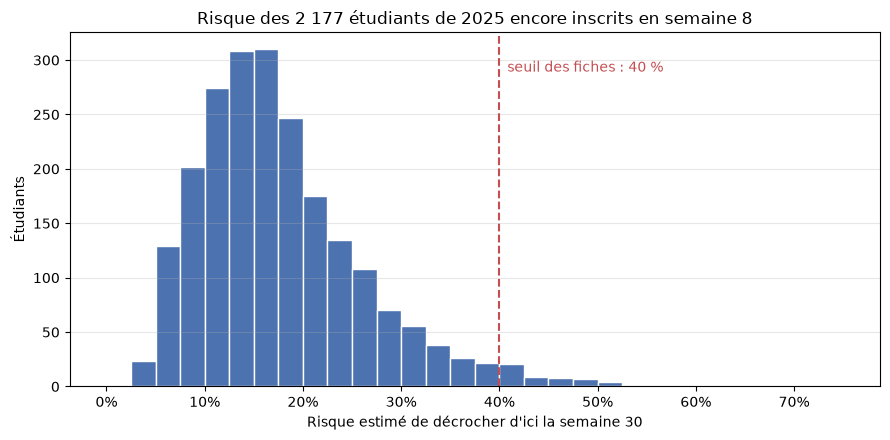

Seuil,30 %,35 %,40 %,45 %,50 %
Étudiants à risque au moins égal,196,102,54,24,9


Risque moyen de la promotion : 17,8 % (médiane 16,2 %). 54 étudiants atteignent 40 % (de 40,0 à 71,0 %, moyenne 45,9 %) : ils reçoivent une fiche.


In [3]:
predictions = llm.lire_resultat("ml_predictions_2025.csv")
population = llm.population_suivie(base, SEMAINE)
risques = llm.risques_conditionnels(predictions, population[config.COLONNE_ID].tolist(), SEMAINE)
seuil = config.SEUIL_RISQUE_FICHE

figure, axe = plt.subplots(figsize=(9, 4.5))
axe.hist(risques, bins=np.arange(0, 0.76, 0.025), color="#4C72B0", edgecolor="white")
axe.axvline(seuil, color="#C44E52", linestyle="--", linewidth=1.5)
axe.text(seuil, axe.get_ylim()[1] * 0.92, f"  seuil des fiches : {nombre(100 * seuil, 0)} %", color="#C44E52",
         fontsize=10, va="top")
axe.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axe.set_xlabel(f"Risque estimé de décrocher d'ici la semaine {config.N_SEMAINES}")
axe.set_ylabel("Étudiants")
axe.set_title(f"Risque des {entier(len(risques))} étudiants de 2025 encore inscrits en semaine {SEMAINE}")
axe.grid(axis="y", alpha=0.3)
enregistrer(figure, "06_risque_semaine8.png")

seuils = [0.30, 0.35, 0.40, 0.45, 0.50]
display(pd.DataFrame({"Seuil": [f"{nombre(100 * s, 0)} %" for s in seuils],
                      "Étudiants à risque au moins égal": [entier((risques >= s).sum()) for s in seuils]}
                     ).set_index("Seuil").T)
retenus = risques >= seuil
print(f"Risque moyen de la promotion : {nombre(100 * risques.mean())} % (médiane {nombre(100 * np.median(risques))} %). "
      f"{entier(retenus.sum())} étudiants atteignent {nombre(100 * seuil, 0)} % (de {nombre(100 * risques[retenus].min())} à "
      f"{nombre(100 * risques[retenus].max())} %, moyenne {nombre(100 * risques[retenus].mean())} %) : ils reçoivent une fiche.")

In [4]:
decroches = (population["E"] == 1).to_numpy()
part_retenus = decroches[retenus].mean()
part_autres = decroches[~retenus].mean()
print("Vérification a posteriori, NON utilisée pour choisir le seuil (validé avant, D-66) :")
print(f"- parmi les {entier(retenus.sum())} étudiants signalés, {entier(decroches[retenus].sum())} ont décroché après la "
      f"semaine {SEMAINE} ({nombre(100 * part_retenus)} %) ;")
print(f"- parmi les {entier((~retenus).sum())} autres, {entier(decroches[~retenus].sum())} ({nombre(100 * part_autres)} %).")
print("Simple proportion : les transferts comptent comme non-décrocheurs, ce qui la sous-estime un peu.")
print(f"Pour un conseiller : un étudiant signalé a décroché {nombre(part_retenus / part_autres)} fois plus souvent que "
      f"les autres ({nombre(100 * part_retenus)} % contre {nombre(100 * part_autres)} %), mais plus de la moitié des étudiants "
      "signalés n'ont pas décroché : la fiche invite à un entretien, elle ne prédit pas l'avenir d'un étudiant."
      if part_retenus < 0.5 else
      f"Pour un conseiller : {nombre(100 * part_retenus)} % des étudiants signalés ont décroché, contre "
      f"{nombre(100 * part_autres)} % des autres.")

Vérification a posteriori, NON utilisée pour choisir le seuil (validé avant, D-66) :
- parmi les 54 étudiants signalés, 23 ont décroché après la semaine 8 (42,6 %) ;
- parmi les 2 123 autres, 387 (18,2 %).
Simple proportion : les transferts comptent comme non-décrocheurs, ce qui la sous-estime un peu.
Pour un conseiller : un étudiant signalé a décroché 2,3 fois plus souvent que les autres (42,6 % contre 18,2 %), mais plus de la moitié des étudiants signalés n'ont pas décroché : la fiche invite à un entretien, elle ne prédit pas l'avenir d'un étudiant.


## 3. Les facteurs affichés

Un facteur est une caractéristique connue à la rentrée qui, dans le Cox, est **associée** à un risque plus élevé : le multiplicateur compare l'étudiant à un étudiant moyen de la promotion, à autres caractéristiques égales. Le genre et la région restent dans le score mais ne sont jamais affichés (D-66). Ce sont des associations, pas des causes.

In [5]:
frequences = collections.Counter(f["facteur"] for e in entrees for f in e["entree"]["facteurs"])
premiers = collections.Counter(e["entree"]["facteurs"][0]["facteur"] for e in entrees if e["entree"]["facteurs"])
tableau_facteurs = pd.DataFrame({
    "Fiches où il apparaît": [frequences.get(libelle, 0) for libelle in config.LIBELLES_FACTEURS_FICHE.values()],
    "Premier facteur": [premiers.get(libelle, 0) for libelle in config.LIBELLES_FACTEURS_FICHE.values()],
}, index=list(config.LIBELLES_FACTEURS_FICHE.values()))
display(tableau_facteurs)
principal = tableau_facteurs["Fiches où il apparaît"].idxmax()
print(f"{entier(sum(frequences.values()))} facteurs affichés en tout dans les {entier(len(entrees))} fiches. Le plus "
      f"fréquent est « {principal} » ({entier(frequences[principal])} fiches) ; il est le premier facteur de "
      f"{entier(premiers[principal])} fiches.")

,Fiches où il apparaît,Premier facteur
âge,29,6
note du bac,45,14
distance domicile-campus,23,3
bourse,13,0
emploi en parallèle des études,52,31
filière,0,0


162 facteurs affichés en tout dans les 54 fiches. Le plus fréquent est « emploi en parallèle des études » (52 fiches) ; il est le premier facteur de 31 fiches.


In [6]:
statuts_fiches = collections.Counter(e["entree"]["tutorat"]["statut"] for e in entrees)
statuts_promotion = collections.Counter(llm.statut_tutorat(ligne, SEMAINE)["statut"] for _, ligne in population.iterrows())
display(pd.DataFrame({"Étudiants signalés": [statuts_fiches.get(s, 0) for s in config.STATUTS_TUTORAT_FICHE],
                      "Promotion": [statuts_promotion.get(s, 0) for s in config.STATUTS_TUTORAT_FICHE]},
                     index=list(config.STATUTS_TUTORAT_FICHE)))
print(f"{entier(statuts_fiches['en cours'])} des {entier(len(entrees))} étudiants signalés ont déjà un tutorat en cours en "
      f"semaine {SEMAINE} : pour eux, le contrôle automatique interdit l'action « proposer un tutorat ».")

,Étudiants signalés,Promotion
en cours,17,402
aucun,37,1774
"signalé, semaine de début inconnue",0,1


17 des 54 étudiants signalés ont déjà un tutorat en cours en semaine 8 : pour eux, le contrôle automatique interdit l'action « proposer un tutorat ».


In [7]:
NOMS_ACTIVITE = {"connexions_plateforme": "Connexions à la plateforme", "devoirs_rendus": "Devoirs rendus",
                 "seances_manquees": "Séances manquées", "note_moyenne": "Note moyenne (sur 20)"}
promotion = entrees[0]["entree"]["activite_promotion"]
signales = {champ: np.mean([e["entree"]["activite"][champ] for e in entrees if e["entree"]["activite"][champ] is not None])
            for champ in NOMS_ACTIVITE}
display(pd.DataFrame({"Étudiants signalés": [round(signales[c], 1) for c in NOMS_ACTIVITE],
                      "Promotion": [promotion[c] for c in NOMS_ACTIVITE]}, index=list(NOMS_ACTIVITE.values())))
print(f"Moyennes par semaine sur les semaines {config.SEMAINES_ACTIVITE_FICHE[0]} et {config.SEMAINES_ACTIVITE_FICHE[1]}, "
      "étudiants signalés contre promotion : "
      + " ; ".join(f"{NOMS_ACTIVITE[c].lower()} {nombre(signales[c])} contre {nombre(promotion[c])}" for c in NOMS_ACTIVITE)
      + ". Ces observations sont décrites dans la fiche ; elles ne font pas partie "
      "du score, qui ne connaît que la rentrée.")

,Étudiants signalés,Promotion
Connexions à la plateforme,4.6,6.1
Devoirs rendus,1.1,1.4
Séances manquées,3.3,2.5
Note moyenne (sur 20),9.1,10.4


Moyennes par semaine sur les semaines 7 et 8, étudiants signalés contre promotion : connexions à la plateforme 4,6 contre 6,1 ; devoirs rendus 1,1 contre 1,4 ; séances manquées 3,3 contre 2,5 ; note moyenne (sur 20) 9,1 contre 10,4. Ces observations sont décrites dans la fiche ; elles ne font pas partie du score, qui ne connaît que la rentrée.


## 4. Ce qui part vers le LLM

Voici, pour le premier étudiant signalé, exactement ce qui serait envoyé : l'entrée (sans identifiant), puis le prompt complet construit à partir du gabarit de la version courante (`fiche_v2.md`, D-69).

In [8]:
premiere = entrees[0]["entree"]
llm.verifier_entree_sans_donnee_personnelle(premiere)
print("Entrée (contrôlée : clés, types, formats ; aucun identifiant, e-mail ni téléphone) :")
print(json.dumps(premiere, ensure_ascii=False, indent=2))

Entrée (contrôlée : clés, types, formats ; aucun identifiant, e-mail ni téléphone) :
{
  "semaine_observation": 8,
  "horizon_semaines": 30,
  "risque_decrochage_pct": 71,
  "risque_moyen_promotion_pct": 18,
  "facteurs": [
    {
      "facteur": "âge",
      "valeur_etudiant": "28 ans",
      "reference_promotion": "20,1 ans en moyenne dans la promotion",
      "multiplicateur": 2.1
    },
    {
      "facteur": "emploi en parallèle des études",
      "valeur_etudiant": "oui",
      "reference_promotion": "18 % de la promotion dans ce cas",
      "multiplicateur": 1.6
    },
    {
      "facteur": "distance domicile-campus",
      "valeur_etudiant": "131 km",
      "reference_promotion": "11 km pour un étudiant typique de la promotion",
      "multiplicateur": 1.5
    }
  ],
  "activite": {
    "semaines": [
      7,
      8
    ],
    "note_maximum": 20,
    "connexions_plateforme": 3.0,
    "devoirs_rendus": 0.5,
    "seances_manquees": 4.5,
    "note_moyenne": 9.0
  },
  "activite_

In [9]:
instructions, message = llm.construire_prompt(premiere)
print(f"Gabarit : fiche_{config.VERSION_PROMPT}.md")
print("===== Instructions système =====")
print(instructions)
print()
print("===== Message =====")
print(message)

Gabarit : fiche_v2.md
===== Instructions système =====
Tu aides un conseiller pédagogique de l'Institut Supérieur Horizon à préparer un entretien avec un étudiant. À partir de l'ENTRÉE (un objet JSON), tu rédiges une fiche courte, factuelle et bienveillante, en français correct (accents compris, par exemple « À la semaine »).

Sens des champs de l'entrée :
- risque_decrochage_pct : risque, estimé par un modèle statistique, que l'étudiant décroche avant la semaine horizon_semaines, sachant qu'il est encore inscrit à la semaine semaine_observation ; risque_moyen_promotion_pct : le même risque, en moyenne, dans sa promotion.
- facteurs : au plus 3 caractéristiques connues dès la rentrée qui, dans le modèle, sont associées à un risque plus élevé. valeur_etudiant : la valeur de l'étudiant ; reference_promotion : la valeur de comparaison dans la promotion ; multiplicateur : dans le modèle, le risque de l'étudiant est multiplié par cette valeur par rapport à celui d'un étudiant moyen de la pr

In [10]:
print("Schéma imposé à la réponse :")
print(json.dumps(llm.schema_fiche(), ensure_ascii=False, indent=2))

Schéma imposé à la réponse :
{
  "type": "object",
  "properties": {
    "situation": {
      "type": "string"
    },
    "points_attention": {
      "type": "array",
      "items": {
        "type": "string"
      },
      "minItems": 2,
      "maxItems": 4
    },
    "actions": {
      "type": "array",
      "items": {
        "type": "string",
        "enum": [
          "entretien individuel",
          "proposer un tutorat",
          "faire le point sur le tutorat en cours",
          "informer sur les aides",
          "aménager l'emploi du temps",
          "suivre l'assiduité",
          "relancer sur les devoirs"
        ]
      },
      "minItems": 2,
      "maxItems": 3
    }
  },
  "required": [
    "situation",
    "points_attention",
    "actions"
  ],
  "additionalProperties": false
}


**Contrôles automatiques de chaque réponse** (`llm.verifier_fiche`) ; une fiche non conforme est redemandée (3 essais au plus), sinon enregistrée « à revoir » avec ses motifs :
- réponse JSON lisible, avec exactement les clés `situation`, `points_attention`, `actions` et les bons types ;
- `situation` non vide, d'au plus 350 caractères ; 2 à 4 points d'attention d'au plus 200 caractères ;
- 2 ou 3 actions distinctes, prises mot pour mot dans la liste fermée ; cohérence avec le tutorat (tutorat en cours : pas « proposer un tutorat » ; aucun tutorat : pas « faire le point sur le tutorat en cours ») ;
- **chaque nombre écrit en chiffres dans la fiche figure dans l'entrée** ;
- aucun mot interdit (minuscules, mots entiers) : causalité, y compris les formes conjuguées (« entraîner », « causent », « du à »…) ; certitude (« décrochera », « sûrement »…) ; jugement de la personne ; attributs sensibles ; circonstances inventées (« familial », « financier », « motivation »…) ; nombres en lettres (« deux » à « dix », « vingt », « quart », « tiers », « quadruple »… ; « un » reste permis) ;
- aucun motif d'identifiant, d'e-mail ou de téléphone.

Les fiches déjà en cache repassent ces contrôles à chaque génération et avec `python -m src.llm --verifier`, sans appel : une fiche qui ne les passe plus devient « à revoir » (D-67, point 3).

**Limites des contrôles (D-67, point 3)** : ils ne voient pas
- un nombre **calculé** qui tombe par hasard sur un nombre de l'entrée (par exemple une différence égale à une autre valeur) ;
- un nombre de l'entrée attribué au **mauvais champ** (le risque de la promotion présenté comme celui de l'étudiant) ;
- une action hors de la liste citée dans un point d'attention (seul le champ `actions` est contrôlé) ;
- plus largement, le sens et le ton d'une phrase.

Ces points sont contrôlés par la relecture humaine de LL-02 (grille d'évaluation).

## 5. Fiches générées

Cette section présente les fiches de la version courante du prompt (v2). Elles ont été générées une fois par `python -m src.llm --generer` et sont enregistrées dans le dépôt (`llm_fiches_semaine8_v2.json`) ; celles de la version 1 sont gardées (`llm_fiches_semaine8_v1.json`) pour la comparaison de la section 6. Chaque fiche est enregistrée avec le modèle, la version du prompt et la date. Une fiche « validée » a passé tous les contrôles automatiques ; une fiche « à revoir » ne les a pas passés en 3 essais et n'est jamais présentée comme validée (D-67, point 9).

In [11]:
fiches = llm.lire_json(config.FICHIER_FICHES_LLM) if config.FICHIER_FICHES_LLM.exists() else []
if not fiches:
    print("Aucune fiche générée : lancer python -m src.llm --generer (clé d'API nécessaire).")
else:
    statuts = collections.Counter(f["statut"] for f in fiches)
    essais = collections.Counter(f["nb_essais"] for f in fiches)
    modeles = ", ".join(sorted({f["modele"] for f in fiches}))
    print(f"{entier(len(fiches))} fiches (modèle {modeles}, prompt {config.VERSION_PROMPT}) : "
          + ", ".join(f"{entier(statuts.get(s, 0))} « {s} »" for s in (config.STATUT_FICHE_VALIDEE, config.STATUT_FICHE_A_REVOIR))
          + ".")
    display(pd.DataFrame({"Fiches": [essais.get(n, 0) for n in range(1, config.NB_ESSAIS_FICHE + 1)]},
                         index=[f"{n} essai(s)" for n in range(1, config.NB_ESSAIS_FICHE + 1)]).T)
    appels = sum(f["nb_essais"] for f in fiches)
    print(f"{entier(appels)} réponses demandées au LLM pour ces fiches ; {entier(essais.get(1, 0))} fiches acceptées "
          "dès le premier essai.")
    motifs = collections.Counter(m.split(" : ")[0] for f in fiches for m in f["motifs_rejet"])
    if motifs:
        display(pd.DataFrame({"Fiches « à revoir »": list(motifs.values())}, index=list(motifs.keys())))
    else:
        print("Aucun motif de rejet sur les fiches enregistrées (les motifs des essais refusés puis "
              "réussis ne sont pas conservés).")

54 fiches (modèle gemini-3.5-flash-lite, prompt v2) : 54 « validée », 0 « à revoir ».


,1 essai(s),2 essai(s),3 essai(s)
Fiches,54,0,0


54 réponses demandées au LLM pour ces fiches ; 54 fiches acceptées dès le premier essai.
Aucun motif de rejet sur les fiches enregistrées (les motifs des essais refusés puis réussis ne sont pas conservés).


In [12]:
def afficher_fiche(fiche, titre):
    """Affiche une fiche comme le conseiller la lirait, sans l'identifiant de l'étudiant."""
    print(f"===== {titre} =====")
    print(f"Risque estimé : {fiche['risque_decrochage_pct']} % ; statut : {fiche['statut']} ; "
          f"tutorat : {fiche['entree']['tutorat']['statut']}")
    if fiche["statut"] != config.STATUT_FICHE_VALIDEE:
        print("À REVOIR : " + " ; ".join(fiche["motifs_rejet"]))
    print(f"Situation : {fiche['situation']}")
    print("Points d'attention :")
    for point in fiche["points_attention"] or []:
        print(f"  - {point}")
    print("Actions proposées : " + ", ".join(fiche["actions"] or []))
    print(f"Avertissement : {fiche['avertissement']}")
    print()


if fiches:
    plus_haut = max(fiches, key=lambda f: f["risque_decrochage_pct"])
    afficher_fiche(plus_haut, "Risque le plus élevé")
    en_tutorat = [f for f in fiches if f["entree"]["tutorat"]["statut"] == "en cours"]
    if en_tutorat:
        afficher_fiche(en_tutorat[0], "Étudiant déjà en tutorat")
    a_revoir = [f for f in fiches if f["statut"] == config.STATUT_FICHE_A_REVOIR]
    if a_revoir:
        afficher_fiche(a_revoir[0], "Fiche « à revoir »")
    else:
        print("Aucune fiche « à revoir » à montrer.")

===== Risque le plus élevé =====
Risque estimé : 71 % ; statut : validée ; tutorat : aucun
Situation : À la semaine 8, le risque estimé que l'étudiant décroche d'ici la semaine 30 est de 71 %, contre 18 % en moyenne dans sa promotion. L'étudiant n'a pas commencé de tutorat.
Points d'attention :
  - Âge : 28 ans (20,1 ans en moyenne dans la promotion) ; ce facteur est associé à un risque multiplié par 2,1 par rapport à un étudiant moyen.
  - Emploi en parallèle des études : oui (18 % de la promotion dans ce cas) ; ce facteur est associé à un risque multiplié par 1,6 par rapport à un étudiant moyen.
  - Distance domicile-campus : 131 km (11 km pour un étudiant typique de la promotion) ; ce facteur est associé à un risque multiplié par 1,5 par rapport à un étudiant moyen.
  - Semaines 7 et 8 : 0,5 devoir rendu par semaine (promotion : 1,4), 4,5 séances manquées par semaine (promotion : 2,5) et une note moyenne de 9,0 / 20 (promotion : 10,4).
Actions proposées : proposer un tutorat, relanc

**Évaluation (LL-02)** : `python -m src.llm --grille` a tiré 20 fiches au hasard (graine fixe) pour chaque version du prompt (`docs/evaluation_fiches_llm_v1.csv` et `_v2.csv`) : ce sont les mêmes 20 étudiants dans les deux versions. Les notes (exactitude, ton, stigmatisation, pertinence des actions, et les limites des contrôles listées en section 4) sont celles de Saliou ; ce notebook ne les donne pas à sa place. La section 6 les compare.

## 6. Évaluation (LL-02) : version 1 puis version 2

La version 1 du prompt a été notée par Saliou (mesure « avant »), puis une version 2 a été écrite et validée par lui (D-69). **Ce qui change dans le gabarit v2** :
- les nombres s'écrivent à la française : virgule décimale et symbole « % » ;
- chaque facteur est écrit avec la valeur de l'étudiant, la référence de la promotion et le multiplicateur, comparé à « un étudiant moyen » de la promotion ;
- le tutorat est décrit dans la situation par une phrase imposée (« L'étudiant n'a pas commencé de tutorat », « suit un tutorat depuis la semaine … ») ;
- un point d'attention décrit l'activité récente (devoirs, séances manquées, note), comparée à la promotion ;
- chaque action s'appuie sur un fait de l'entrée ; « entretien individuel » n'est plus proposé par défaut, puisque la fiche prépare déjà un entretien.

**Ce qui ne change pas** : les 54 entrées (identiques octet pour octet), les champs envoyés, les contrôles bloquants, le schéma de la réponse, la liste des actions et le modèle `gemini-3.5-flash-lite`. La comparaison porte donc sur le seul prompt.

Les **indicateurs automatiques** ci-dessous comptent des motifs simples dans le texte des fiches (`llm.resume_indicateurs`) ; ils servent à évaluer, jamais à rejeter une fiche.

In [13]:
fiches_par_version = {v: llm.lire_json(chemin) for v, chemin in config.FICHIERS_FICHES_LLM.items() if chemin.exists()}
indicateurs = {v: llm.resume_indicateurs(f) for v, f in fiches_par_version.items()}


def part(nombre_, sur):
    """« n / N (x %) », ou « n » quand il n'y a pas de dénominateur."""
    if pd.isna(sur):
        return entier(nombre_)
    if sur == 0:
        return f"0 / 0"
    return f"{entier(nombre_)} / {entier(sur)} ({nombre(100 * nombre_ / sur, 0)} %)"


comparaison = indicateurs["v1"][["groupe", "indicateur"]].copy()
for version, tableau in indicateurs.items():
    comparaison[version] = [part(n, s) for n, s in zip(tableau["nombre"], tableau["sur"])]
display(comparaison.set_index(["groupe", "indicateur"]))

v1                 v2
groupe    indicateur                                                                               
contrôles Fiches validées                                        54 / 54 (100 %)    54 / 54 (100 %)
          Validées dès le premier essai                           48 / 54 (89 %)    54 / 54 (100 %)
forme     Nombre décimal écrit avec un point                      48 / 54 (89 %)       0 / 54 (0 %)
          Tutorat formulé « est aucun » ou « statut aucun »       24 / 54 (44 %)       0 / 54 (0 %)
          Nom de champ « semaine d'observation »                  23 / 54 (43 %)       0 / 54 (0 %)
facteurs  Multiplicateur comparé à « un étudiant moyen »            5 / 54 (9 %)    54 / 54 (100 %)
          Valeur de l'étudiant citée (facteurs chiffrés)          86 / 97 (89 %)    97 / 97 (100 %)
          Référence de la promotion citée                        85 / 162 (52 %)  162 / 162 (100 %)
actions   Au moins une action qu'aucun fait n'appuie              22 / 54 (41 %)       2 / 54 (4 %)
          Action appuyée oubliée alors qu'une place restait       53 / 54 (98 %)       0 / 54 (0 %)
          « entretien individuel » proposé                       54 / 54 (100 %)       2 / 54 (4 %)
          « aménager l'emploi du temps » quand un fait l'appuie     0 / 52 (0 %)     45 / 52 (87 %)
          « informer sur les aides » quand un fait l'appuie         0 / 13 (0 %)      7 / 13 (54 %)
          « relancer sur les devoirs » quand un fait l'appuie      6 / 29 (21 %)     20 / 29 (69 %)
          « suivre l'assiduité » quand un fait l'appuie           26 / 28 (93 %)     27 / 28 (96 %)
          Combinaisons d'actions différentes                                   4                 12

In [14]:
def ligne(version, indicateur):
    """(nombre, sur) d'un indicateur pour une version."""
    tableau = indicateurs[version].set_index("indicateur")
    return int(tableau.loc[indicateur, "nombre"]), tableau.loc[indicateur, "sur"]


def evolution(indicateur):
    """« n1 / N1 en v1, n2 / N2 en v2 »."""
    (n1, s1), (n2, s2) = ligne("v1", indicateur), ligne("v2", indicateur)
    return f"{part(n1, s1)} en v1, {part(n2, s2)} en v2"


validees_v2, total_v2 = ligne("v2", "Fiches validées")
print(f"Contrôles : fiches validées {evolution('Fiches validées')} ; dès le premier essai "
      f"{evolution('Validées dès le premier essai')}. Les contrôles bloquants sont les mêmes dans les deux versions : "
      "les deux jeux de fiches respectent les mêmes garde-fous (nombres de l'entrée, mots interdits, liste d'actions).")
print()
defauts_v2 = sum(ligne("v2", i)[0] for i in ["Nombre décimal écrit avec un point",
                                              "Tutorat formulé « est aucun » ou « statut aucun »",
                                              "Nom de champ « semaine d'observation »"])
print("Forme : nombre décimal écrit avec un point " + evolution("Nombre décimal écrit avec un point")
      + " ; « le statut est aucun » " + evolution("Tutorat formulé « est aucun » ou « statut aucun »")
      + " ; « semaine d'observation » " + evolution("Nom de champ « semaine d'observation »") + ". "
      + ("Pour un conseiller : les fiches v2 se lisent comme un texte en français, sans vocabulaire de fichier."
         if defauts_v2 == 0 else f"Pour un conseiller : il reste {entier(defauts_v2)} défaut(s) d'écriture en v2."))
print()
print("Facteurs : multiplicateur comparé à « un étudiant moyen » "
      + evolution("Multiplicateur comparé à « un étudiant moyen »") + " ; valeur de l'étudiant citée "
      + evolution("Valeur de l'étudiant citée (facteurs chiffrés)") + " ; référence de la promotion citée "
      + evolution("Référence de la promotion citée") + ". Pour un conseiller : un multiplicateur seul (« 1,6 ») "
      "ne dit rien ; avec la valeur de l'étudiant, celle de la promotion et la comparaison à un étudiant moyen, "
      "il peut l'expliquer à l'étudiant.")
print()
combinaisons = "Combinaisons d'actions différentes"
print("Actions : action qu'aucun fait n'appuie " + evolution("Au moins une action qu'aucun fait n'appuie")
      + " ; « entretien individuel » proposé " + evolution("« entretien individuel » proposé")
      + " ; action appuyée oubliée alors qu'une place restait "
      + evolution("Action appuyée oubliée alors qu'une place restait") + " ; « aménager l'emploi du temps » "
      "quand un fait l'appuie " + evolution("« aménager l'emploi du temps » quand un fait l'appuie")
      + f" ; combinaisons d'actions différentes : {ligne('v1', combinaisons)[0]} en v1, "
      f"{ligne('v2', combinaisons)[0]} en v2. Pour un conseiller : plus les actions varient d'une fiche à "
      "l'autre, plus elles suivent la situation de chaque étudiant (emploi, devoirs, assiduité) plutôt qu'un même "
      "choix pour presque tous. Une fiche peut avoir plus d'actions appuyées que de places (3 au plus) : les "
      "lignes « quand un fait l'appuie » n'ont pas à atteindre 100 %.")

Contrôles : fiches validées 54 / 54 (100 %) en v1, 54 / 54 (100 %) en v2 ; dès le premier essai 48 / 54 (89 %) en v1, 54 / 54 (100 %) en v2. Les contrôles bloquants sont les mêmes dans les deux versions : les deux jeux de fiches respectent les mêmes garde-fous (nombres de l'entrée, mots interdits, liste d'actions).

Forme : nombre décimal écrit avec un point 48 / 54 (89 %) en v1, 0 / 54 (0 %) en v2 ; « le statut est aucun » 24 / 54 (44 %) en v1, 0 / 54 (0 %) en v2 ; « semaine d'observation » 23 / 54 (43 %) en v1, 0 / 54 (0 %) en v2. Pour un conseiller : les fiches v2 se lisent comme un texte en français, sans vocabulaire de fichier.

Facteurs : multiplicateur comparé à « un étudiant moyen » 5 / 54 (9 %) en v1, 54 / 54 (100 %) en v2 ; valeur de l'étudiant citée 86 / 97 (89 %) en v1, 97 / 97 (100 %) en v2 ; référence de la promotion citée 85 / 162 (52 %) en v1, 162 / 162 (100 %) en v2. Pour un conseiller : un multiplicateur seul (« 1,6 ») ne dit rien ; avec la valeur de l'étudiant, celle

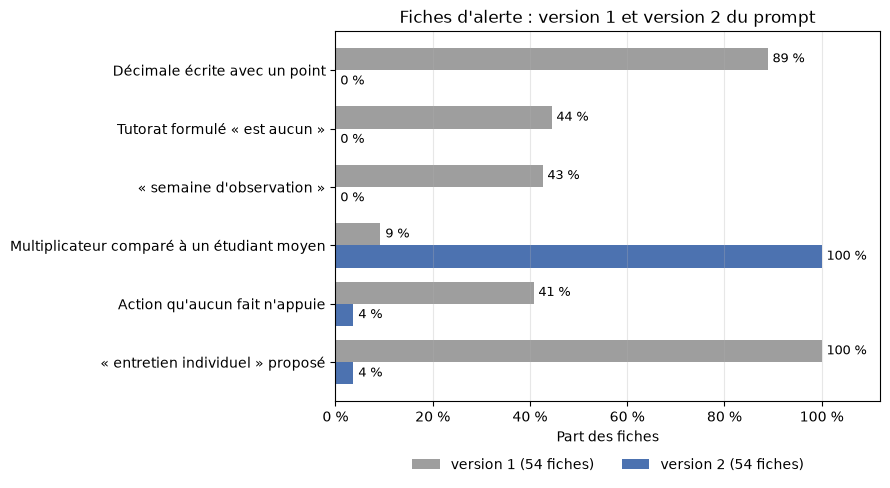

Chaque barre mesure un défaut visé par la version 2 (plus courte = mieux), sauf « Multiplicateur comparé à un étudiant moyen », qui mesure une qualité attendue (plus longue = mieux).


In [15]:
INDICATEURS_FIGURE = {
    "Nombre décimal écrit avec un point": "Décimale écrite avec un point",
    "Tutorat formulé « est aucun » ou « statut aucun »": "Tutorat formulé « est aucun »",
    "Nom de champ « semaine d'observation »": "« semaine d'observation »",
    "Multiplicateur comparé à « un étudiant moyen »": "Multiplicateur comparé à un étudiant moyen",
    "Au moins une action qu'aucun fait n'appuie": "Action qu'aucun fait n'appuie",
    "« entretien individuel » proposé": "« entretien individuel » proposé",
}
COULEURS_VERSIONS = {"v1": "#9E9E9E", "v2": "#4C72B0"}
positions = np.arange(len(INDICATEURS_FIGURE))
hauteur = 0.38
figure, axe = plt.subplots(figsize=(9, 5))
for decalage, version in zip((-hauteur / 2, hauteur / 2), ("v1", "v2")):
    parts = [ligne(version, i)[0] / ligne(version, i)[1] for i in INDICATEURS_FIGURE]
    barres = axe.barh(positions + decalage, parts, height=hauteur, color=COULEURS_VERSIONS[version],
                      label=f"version {version[1]} ({entier(len(fiches_par_version[version]))} fiches)")
    for barre, valeur in zip(barres, parts):
        axe.text(valeur + 0.01, barre.get_y() + barre.get_height() / 2, f"{nombre(100 * valeur, 0)} %",
                 va="center", fontsize=9)
axe.set_yticks(positions, list(INDICATEURS_FIGURE.values()))
axe.invert_yaxis()
axe.set_xlim(0, 1.12)
axe.set_xticks(np.arange(0, 1.01, 0.2), [f"{nombre(100 * x, 0)} %" for x in np.arange(0, 1.01, 0.2)])
axe.set_xlabel("Part des fiches")
axe.set_title("Fiches d'alerte : version 1 et version 2 du prompt")
axe.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
axe.grid(axis="x", alpha=0.3)
enregistrer(figure, "06_comparaison_prompts.png")
print("Chaque barre mesure un défaut visé par la version 2 (plus courte = mieux), sauf « Multiplicateur comparé "
      "à un étudiant moyen », qui mesure une qualité attendue (plus longue = mieux).")

**Notes humaines** (grilles de Saliou, lues et contrôlées par `llm.lire_grille_evaluation`, résumées par `llm.resume_grille`) : moyennes et comptes sur les fiches entièrement notées. Ton et pertinence des actions sont notés de 1 à 3 (3 = meilleur).

In [16]:
NOMS_NOTES = {"fiches_notees": "Fiches entièrement notées", "exactitude_oui": "Exactitude jugée bonne (« oui »)",
              "ton_moyen": "Ton moyen (1 à 3)", "stigmatisation_oui": "Fiches jugées stigmatisantes",
              "actions_pertinentes_moyennes": "Pertinence moyenne des actions (1 à 3)",
              "commentaires": "Commentaires écrits"}
notes = {}
for version, chemin in config.FICHIERS_GRILLE_EVALUATION.items():
    resume = llm.resume_grille(llm.lire_grille_evaluation(chemin)) if chemin.exists() else None
    if resume is None or resume["fiches_notees"] == 0:
        notes[version] = {cle: "en attente de la notation de Saliou" for cle in NOMS_NOTES}
    else:
        notes[version] = {cle: (nombre(valeur, 2) if isinstance(valeur, float) else entier(valeur))
                          for cle, valeur in resume.items()}
display(pd.DataFrame(notes, index=list(NOMS_NOTES)).rename(index=NOMS_NOTES))
en_attente = [v for v in notes if notes[v]["fiches_notees"] == "en attente de la notation de Saliou"]
if en_attente:
    print(f"Grille(s) {', '.join(en_attente)} pas encore notée(s) : la comparaison des notes humaines viendra "
          "après la notation de Saliou.")
else:
    print("Mêmes 20 étudiants dans les deux grilles : un écart de notes ne vient pas du choix des fiches ; il "
          "peut venir du prompt, mais aussi du hasard de la génération et du jugement d'une seule personne qui "
          "connaît la version (voir les limites ci-dessous).")

,v1,v2
Fiches entièrement notées,20,20
Exactitude jugée bonne (« oui »),20,20
Ton moyen (1 à 3),"2,00","2,00"
Fiches jugées stigmatisantes,0,0
Pertinence moyenne des actions (1 à 3),"2,95","2,85"
Commentaires écrits,0,0


Mêmes 20 étudiants dans les deux grilles : un écart de notes ne vient pas du choix des fiches ; il peut venir du prompt, mais aussi du hasard de la génération et du jugement d'une seule personne qui connaît la version (voir les limites ci-dessous).


**Une même fiche en version 1 puis en version 2** : l'étudiant au risque le plus élevé (même entrée dans les deux versions ; identifiant non affiché).

In [17]:
plus_haut_v1 = max(fiches_par_version["v1"], key=lambda f: f["risque_decrochage_pct"])
meme_v2 = [f for f in fiches_par_version["v2"] if f["id_etudiant"] == plus_haut_v1["id_etudiant"]]
afficher_fiche(plus_haut_v1, "Version 1")
if meme_v2:
    assert meme_v2[0]["entree"] == plus_haut_v1["entree"]
    afficher_fiche(meme_v2[0], "Version 2 (même entrée)")
else:
    print("Pas encore de fiche v2 pour cet étudiant.")

===== Version 1 =====
Risque estimé : 71 % ; statut : validée ; tutorat : aucun
Situation : Le risque estimé de décrochage avant la semaine 30, sachant que l'étudiant est encore inscrit à la semaine 8, est de 71 %, contre 18 % en moyenne dans la promotion. Ce risque est associé à plusieurs facteurs connus dès la rentrée, dont l'âge et la distance domicile-campus.
Points d'attention :
  - L'âge est de 28 ans, associé à un multiplicateur de 2.1.
  - L'emploi en parallèle des études est présent, associé à un multiplicateur de 1.6.
  - La distance domicile-campus est de 131 km, associée à un multiplicateur de 1.5.
  - Durant les semaines 7 à 8, la moyenne des devoirs rendus est de 0.5 et la moyenne des séances manquées est de 4.5.
Actions proposées : entretien individuel, proposer un tutorat, suivre l'assiduité
Avertissement : Fiche générée automatiquement à partir d'un modèle statistique : à vérifier par le conseiller. Les facteurs sont des associations, pas des causes.

===== Version 2 (

**Limites de cette évaluation** :
- **une seule personne note**, Saliou, et elle sait quelle version elle lit : ses notes peuvent être influencées par ce qu'elle attend de la v2 ;
- les **indicateurs automatiques** suivent des règles simples (un motif dans le texte, un fait de l'entrée) : ils ne jugent ni le ton ni l'utilité réelle d'une fiche pour un conseiller ;
- les deux versions ont **les mêmes entrées et les mêmes contrôles bloquants** : une différence vient du seul prompt, mais aussi du hasard de la génération (une seule génération par version) ;
- 20 fiches notées sur 54 : l'échantillon est petit, les écarts de notes de quelques fiches sont fragiles.